# Importamos librerías

In [48]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [49]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import AveragePooling2D
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [50]:
tf.test.is_gpu_available()

True

# Importamos los datos

In [51]:
path = '../../../data/clean/Campo 20 puntos'

## Datos de entrenamiento

### Datos

In [52]:
campvectrain = np.load(path + '/campvectrain.npy')
campvectrain = np.transpose(campvectrain, (0,2,3,1))

In [53]:
np.shape(campvectrain)

(7000, 20, 20, 2)

### Coeficientes

In [54]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [55]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [56]:
campvectest = np.load(path + '/campvectest.npy')
campvectest = np.transpose(campvectest, (0,2,3,1))

In [57]:
np.shape(campvectest)

(1000, 20, 20, 2)

### Coeficientes

In [58]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [59]:
np.shape(coefcampvectest)

(1000, 7)

## Datos de validación

### Datos

In [60]:
campvecval = np.load(path + '/campvecval.npy')
campvecval = np.transpose(campvecval, (0,2,3,1))

In [61]:
np.shape(campvecval)

(2000, 20, 20, 2)

### Coeficienes

In [62]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [63]:
np.shape(coefcampvecval)

(2000, 7)

# Unimos coeficientes con los datos

In [64]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [65]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(20, 20, 2), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [66]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creación del modelo

In [67]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [68]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [69]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [70]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166

In [ ]:
import optuna
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l1, l2

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 1000,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(scheduler)

def objective(trial):
    model = Sequential()
    n_conv_layers = trial.suggest_int("n_conv_layers", 1, 5)
    
    input_shape = (20, 20, 2)  # Tus dimensiones de entrada
    current_shape = input_shape
    
    for i in range(n_conv_layers):
        num_filters = trial.suggest_int(f"num_filters_{i+1}", 8, 64)
        filter_size1 = trial.suggest_int(f"filter_size1_{i+1}", 2, 5)
        filter_size2 = trial.suggest_int(f"filter_size2_{i+1}", 2, 5)
        activation = trial.suggest_categorical(f"activation_{i+1}", ['relu', 'tanh', 'sigmoid'])
        kernel_initializer = trial.suggest_categorical(f"kernel_initializer_{i+1}", ['HeNormal', 'glorot_uniform', 'random_normal'])
        kernel_regularizer = trial.suggest_categorical(f"kernel_regularizer_{i+1}", ['l1', 'l2'])
        
        regularizer = None
        if kernel_regularizer == 'l1':
            regularizer = l1(0.001)
        elif kernel_regularizer == 'l2':
            regularizer = l2(0.001)
            
            
        if (current_shape[0] - filter_size1 + 1 > 0) and (current_shape[1] - filter_size2 + 1 > 0):
            if i == 0:
                model.add(Conv2D(num_filters, (filter_size1, filter_size2), activation=activation, input_shape=input_shape, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
            else:
                model.add(Conv2D(num_filters, (filter_size1, filter_size2), activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
            
            current_shape = (current_shape[0] - filter_size1 + 1, current_shape[1] - filter_size2 + 1, num_filters)
            
        # Decide si agregar una capa de MaxPooling después de esta capa convolucional
        add_maxpooling = trial.suggest_categorical(f"add_maxpooling_after_conv_{i+1}", [True, False])
        if add_maxpooling:
            if current_shape[0] >= 2 and current_shape[1] >= 2:  # Asegurarse de que ambas dimensiones son suficientes para MaxPooling
                model.add(MaxPooling2D(pool_size=(2, 2)))
                current_shape = (current_shape[0] // 2, current_shape[1] // 2, current_shape[2])
        
    model.add(Flatten())
    n_dense_layers = trial.suggest_int("n_dense_layers", 1, 5)
    
    for i in range(n_dense_layers):
        num_units = trial.suggest_int(f"num_units_{i+1}", 16, 128)
        activation = trial.suggest_categorical(f"dense_activation_{i+1}", ['relu', 'tanh', 'sigmoid'])
        kernel_initializer = trial.suggest_categorical(f"dense_kernel_initializer_{i+1}", ['HeNormal', 'glorot_uniform', 'random_normal'])
        kernel_regularizer = trial.suggest_categorical(f"dense_kernel_regularizer_{i+1}", ['l1', 'l2'])

        regularizer = None
        if kernel_regularizer == 'l1':
            regularizer = l1(0.001)
        elif kernel_regularizer == 'l2':
            regularizer = l2(0.001)

        model.add(Dense(num_units, activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
    
        # Decide si agregar una capa de Dropout después de esta capa densa
        add_dropout = trial.suggest_categorical(f"add_dropout_after_dense_{i+1}", [True, False])
        if add_dropout:
            dropout_rate = trial.suggest_float(f"dropout_rate_after_dense_{i+1}", 0.1, 0.5)
            model.add(Dropout(dropout_rate))
            
    model.add(Dense(7, activation=custom_activation))
        
    optimizer = Adam(learning_rate=0.001, clipvalue=100.0)
        
    model.compile(optimizer=optimizer, loss= 'mean_squared_error', metrics=metrics)
    
    history = model.fit(
        train_dataset, 
        validation_data=val_dataset, 
        epochs=20,  
        callbacks=[reduce_lr, early_stop]
    )
    
    val_mean_metric = history.history['val_mean_metric'][-1]
    
    return val_mean_metric

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=300)

print(f'Número de trials finalizados: {len(study.trials)}')
print(f'Mejor trial:')
trial = study.best_trial

print(f'  Valor: {trial.value}')
print('  Parámetros: ')
for key, value in trial.params.items():
    print(f'    {key}: {value}')

[I 2023-09-21 17:27:37,755] A new study created in memory with name: no-name-84fcbf94-aff0-4245-8d9e-025bd78ebfe2


Epoch 1/20
70/70 [==============================] - 2s 14ms/step - loss: 9.4829 - a_1: 2.7392 - a_2: 2.7706 - b_1: 2.6432 - b_2: 2.5563 - d_1: 1.5754 - d_2: 1.6877 - n: 1.5392 - mean_metric: 0.5130 - val_loss: 8.1105 - val_a_1: 2.7144 - val_a_2: 2.7898 - val_b_1: 2.4775 - val_b_2: 2.1614 - val_d_1: 1.0031 - val_d_2: 1.1095 - val_n: 1.4584 - val_mean_metric: 0.4491 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 10ms/step - loss: 7.1308 - a_1: 2.6230 - a_2: 2.7232 - b_1: 2.0464 - b_2: 1.5348 - d_1: 0.9294 - d_2: 1.0183 - n: 1.4787 - mean_metric: 0.4085 - val_loss: 5.8066 - val_a_1: 2.4895 - val_a_2: 2.6861 - val_b_1: 1.1028 - val_b_2: 0.9572 - val_d_1: 0.6340 - val_d_2: 0.7298 - val_n: 1.4028 - val_mean_metric: 0.3275 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 10ms/step - loss: 5.2642 - a_1: 2.1895 - a_2: 2.5770 - b_1: 0.9270 - b_2: 0.8754 - d_1: 0.5374 - d_2: 0.6218 - n: 1.3897 - mean_metric: 0.3015 - val_loss: 4.7594 - val_a_1: 1.8849 - val

[I 2023-09-21 17:27:52,852] Trial 0 finished with value: 0.1680022031068802 and parameters: {'n_conv_layers': 3, 'num_filters_1': 44, 'filter_size1_1': 2, 'filter_size2_1': 5, 'activation_1': 'sigmoid', 'kernel_initializer_1': 'random_normal', 'kernel_regularizer_1': 'l2', 'add_maxpooling_after_conv_1': True, 'num_filters_2': 44, 'filter_size1_2': 2, 'filter_size2_2': 2, 'activation_2': 'tanh', 'kernel_initializer_2': 'HeNormal', 'kernel_regularizer_2': 'l1', 'add_maxpooling_after_conv_2': True, 'num_filters_3': 8, 'filter_size1_3': 2, 'filter_size2_3': 3, 'activation_3': 'relu', 'kernel_initializer_3': 'random_normal', 'kernel_regularizer_3': 'l1', 'add_maxpooling_after_conv_3': True, 'n_dense_layers': 2, 'num_units_1': 63, 'dense_activation_1': 'sigmoid', 'dense_kernel_initializer_1': 'HeNormal', 'dense_kernel_regularizer_1': 'l1', 'add_dropout_after_dense_1': False, 'num_units_2': 128, 'dense_activation_2': 'tanh', 'dense_kernel_initializer_2': 'HeNormal', 'dense_kernel_regularizer_

Epoch 1/20
70/70 [==============================] - 2s 17ms/step - loss: 10.2241 - a_1: 2.7815 - a_2: 2.7892 - b_1: 2.6767 - b_2: 2.6384 - d_1: 1.5418 - d_2: 1.5528 - n: 1.6032 - mean_metric: 0.5155 - val_loss: 8.2452 - val_a_1: 2.7095 - val_a_2: 2.7319 - val_b_1: 2.5988 - val_b_2: 1.9026 - val_d_1: 0.9675 - val_d_2: 0.8115 - val_n: 1.4690 - val_mean_metric: 0.4320 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 14ms/step - loss: 7.2094 - a_1: 2.6329 - a_2: 2.5484 - b_1: 2.3050 - b_2: 1.1715 - d_1: 0.9490 - d_2: 0.7421 - n: 1.4647 - mean_metric: 0.3906 - val_loss: 6.1823 - val_a_1: 2.4949 - val_a_2: 2.3794 - val_b_1: 1.8513 - val_b_2: 0.8697 - val_d_1: 0.6960 - val_d_2: 0.5301 - val_n: 1.4028 - val_mean_metric: 0.3348 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 14ms/step - loss: 5.5557 - a_1: 2.2539 - a_2: 2.1837 - b_1: 1.4525 - b_2: 0.9586 - d_1: 0.7102 - d_2: 0.7142 - n: 1.3616 - mean_metric: 0.3186 - val_loss: 4.7265 - val_a_1: 1.7674 - va

[I 2023-09-21 17:28:13,657] Trial 1 finished with value: 0.16338559985160828 and parameters: {'n_conv_layers': 4, 'num_filters_1': 16, 'filter_size1_1': 3, 'filter_size2_1': 3, 'activation_1': 'relu', 'kernel_initializer_1': 'glorot_uniform', 'kernel_regularizer_1': 'l1', 'add_maxpooling_after_conv_1': False, 'num_filters_2': 33, 'filter_size1_2': 2, 'filter_size2_2': 5, 'activation_2': 'relu', 'kernel_initializer_2': 'random_normal', 'kernel_regularizer_2': 'l2', 'add_maxpooling_after_conv_2': True, 'num_filters_3': 38, 'filter_size1_3': 5, 'filter_size2_3': 2, 'activation_3': 'sigmoid', 'kernel_initializer_3': 'random_normal', 'kernel_regularizer_3': 'l1', 'add_maxpooling_after_conv_3': False, 'num_filters_4': 20, 'filter_size1_4': 4, 'filter_size2_4': 4, 'activation_4': 'sigmoid', 'kernel_initializer_4': 'HeNormal', 'kernel_regularizer_4': 'l1', 'add_maxpooling_after_conv_4': True, 'n_dense_layers': 3, 'num_units_1': 122, 'dense_activation_1': 'relu', 'dense_kernel_initializer_1': '

Epoch 1/20
70/70 [==============================] - 2s 15ms/step - loss: 9.3128 - a_1: 2.7620 - a_2: 2.7687 - b_1: 2.7524 - b_2: 2.7353 - d_1: 2.5948 - d_2: 2.1725 - n: 1.5635 - mean_metric: 0.5737 - val_loss: 7.8903 - val_a_1: 2.7308 - val_a_2: 2.7874 - val_b_1: 2.6544 - val_b_2: 2.5436 - val_d_1: 2.1461 - val_d_2: 1.4385 - val_n: 1.4964 - val_mean_metric: 0.5174 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 13ms/step - loss: 7.4922 - a_1: 2.7313 - a_2: 2.7537 - b_1: 2.6328 - b_2: 2.5152 - d_1: 1.6126 - d_2: 1.4654 - n: 1.5174 - mean_metric: 0.5035 - val_loss: 6.8192 - val_a_1: 2.7218 - val_a_2: 2.7798 - val_b_1: 2.6051 - val_b_2: 2.2922 - val_d_1: 1.1655 - val_d_2: 1.1883 - val_n: 1.4853 - val_mean_metric: 0.4663 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 13ms/step - loss: 6.9909 - a_1: 2.7243 - a_2: 2.7410 - b_1: 2.6058 - b_2: 2.3863 - d_1: 1.2617 - d_2: 1.3125 - n: 1.5066 - mean_metric: 0.4807 - val_loss: 6.6265 - val_a_1: 2.7168 - val

... (8 outputs left out)

[I 2023-09-21 17:30:25,172] Trial 6 finished with value: 0.5159140229225159 and parameters: {'n_conv_layers': 2, 'num_filters_1': 16, 'filter_size1_1': 5, 'filter_size2_1': 5, 'activation_1': 'relu', 'kernel_initializer_1': 'HeNormal', 'kernel_regularizer_1': 'l1', 'add_maxpooling_after_conv_1': False, 'num_filters_2': 42, 'filter_size1_2': 5, 'filter_size2_2': 5, 'activation_2': 'sigmoid', 'kernel_initializer_2': 'HeNormal', 'kernel_regularizer_2': 'l1', 'add_maxpooling_after_conv_2': False, 'n_dense_layers': 4, 'num_units_1': 113, 'dense_activation_1': 'sigmoid', 'dense_kernel_initializer_1': 'glorot_uniform', 'dense_kernel_regularizer_1': 'l1', 'add_dropout_after_dense_1': True, 'dropout_rate_after_dense_1': 0.35690235823579297, 'num_units_2': 36, 'dense_activation_2': 'tanh', 'dense_kernel_initializer_2': 'glorot_uniform', 'dense_kernel_regularizer_2': 'l1', 'add_dropout_after_dense_2': False, 'num_units_3': 114, 'dense_activation_3': 'sigmoid', 'dense_kernel_initializer_3': 'gloro

Epoch 1/20
70/70 [==============================] - 1s 14ms/step - loss: 6.8191 - a_1: 2.7580 - a_2: 2.7931 - b_1: 2.3833 - b_2: 2.2776 - d_1: 1.0554 - d_2: 1.0999 - n: 1.5960 - mean_metric: 0.4618 - val_loss: 4.7678 - val_a_1: 2.6670 - val_a_2: 2.7374 - val_b_1: 1.4521 - val_b_2: 1.3698 - val_d_1: 0.7245 - val_d_2: 0.8987 - val_n: 1.4318 - val_mean_metric: 0.3695 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 12ms/step - loss: 4.2698 - a_1: 2.5726 - a_2: 2.6419 - b_1: 1.0671 - b_2: 1.0642 - d_1: 0.6605 - d_2: 0.7140 - n: 1.4891 - mean_metric: 0.3376 - val_loss: 3.4528 - val_a_1: 2.3134 - val_a_2: 2.3807 - val_b_1: 0.9234 - val_b_2: 1.0293 - val_d_1: 0.4538 - val_d_2: 0.5471 - val_n: 1.3585 - val_mean_metric: 0.2949 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 12ms/step - loss: 2.8912 - a_1: 1.9408 - a_2: 1.9034 - b_1: 0.9275 - b_2: 0.9478 - d_1: 0.5853 - d_2: 0.5750 - n: 1.3323 - mean_metric: 0.2716 - val_loss: 2.2732 - val_a_1: 1.5702 - val

[I 2023-09-21 17:30:42,513] Trial 7 finished with value: 0.17730307579040527 and parameters: {'n_conv_layers': 2, 'num_filters_1': 39, 'filter_size1_1': 3, 'filter_size2_1': 3, 'activation_1': 'sigmoid', 'kernel_initializer_1': 'random_normal', 'kernel_regularizer_1': 'l2', 'add_maxpooling_after_conv_1': True, 'num_filters_2': 15, 'filter_size1_2': 4, 'filter_size2_2': 5, 'activation_2': 'relu', 'kernel_initializer_2': 'HeNormal', 'kernel_regularizer_2': 'l1', 'add_maxpooling_after_conv_2': False, 'n_dense_layers': 1, 'num_units_1': 66, 'dense_activation_1': 'tanh', 'dense_kernel_initializer_1': 'glorot_uniform', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': True, 'dropout_rate_after_dense_1': 0.17237365825305676}. Best is trial 3 with value: 0.13375936448574066.


Epoch 1/20
70/70 [==============================] - 2s 27ms/step - loss: 10.4075 - a_1: 2.7240 - a_2: 2.7580 - b_1: 2.7129 - b_2: 2.7532 - d_1: 2.5714 - d_2: 2.5958 - n: 1.6166 - mean_metric: 0.5863 - val_loss: 8.7330 - val_a_1: 2.7214 - val_a_2: 2.8023 - val_b_1: 2.6968 - val_b_2: 2.6727 - val_d_1: 1.9720 - val_d_2: 2.1320 - val_n: 1.5212 - val_mean_metric: 0.5409 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 2s 24ms/step - loss: 8.4622 - a_1: 2.7244 - a_2: 2.7594 - b_1: 2.6834 - b_2: 2.7454 - d_1: 1.9031 - d_2: 2.0782 - n: 1.5374 - mean_metric: 0.5433 - val_loss: 7.9305 - val_a_1: 2.7270 - val_a_2: 2.7933 - val_b_1: 2.6789 - val_b_2: 2.6598 - val_d_1: 1.7409 - val_d_2: 1.8379 - val_n: 1.4750 - val_mean_metric: 0.5211 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 2s 24ms/step - loss: 7.9994 - a_1: 2.7220 - a_2: 2.7562 - b_1: 2.6806 - b_2: 2.7359 - d_1: 1.7664 - d_2: 1.8606 - n: 1.5233 - mean_metric: 0.5306 - val_loss: 7.6828 - val_a_1: 2.7260 - va

# Entrenamos el modelo

In [71]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l1, l2

# Inicializar el modelo
model = Sequential()

# Primera capa convolucional
model.add(Conv2D(58, (4, 1), activation='relu', input_shape=(20, 20, 2), kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Aplanar
model.add(Flatten())

# Primera capa densa
model.add(Dense(28, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l1(0.001)))

# Segunda capa densa
model.add(Dense(41, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l1(0.001)))

# Tercera capa densa
model.add(Dense(120, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l1(0.001)))

# Dropout
model.add(Dropout(0.3))

# Capa de salida (Asumiendo que custom_activation es 'relu' o alguna otra función de activación que ya tienes)
model.add(Dense(7, activation=custom_activation))


# Resumen del modelo para verificar la arquitectura
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 17, 20, 58)        522       
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 8, 10, 58)        0         
 2D)                                                             
                                                                 
 flatten_3 (Flatten)         (None, 4640)              0         
                                                                 
 dense_12 (Dense)            (None, 28)                129948    
                                                                 
 dense_13 (Dense)            (None, 41)                1189      
                                                                 
 dense_14 (Dense)            (None, 120)               5040      
                                                      

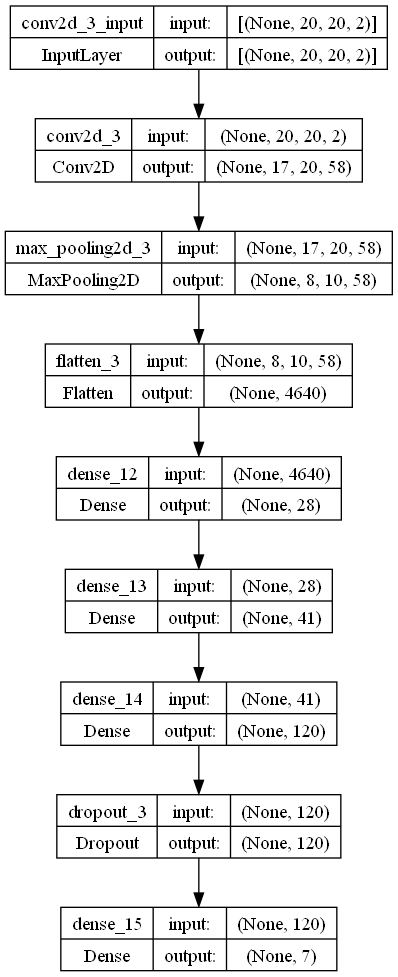

In [72]:
keras.utils.plot_model(model,show_shapes=True)

In [73]:
from keras.optimizers import Adam

optimizer = Adam(learning_rate=0.001, clipvalue=100.0)
model.compile(optimizer=optimizer,
              loss='mean_squared_error',
              metrics=[metrics])

In [74]:
def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.0001  # Updated final learning rate
    start_decay_epoch = 100
    end_decay_epoch = 10000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

In [76]:
def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.00001  # Updated final learning rate
    start_decay_epoch = 30
    end_decay_epoch = 1000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

val_epochs = 1000

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_mean_metric', patience = 100,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/1000
70/70 [==============================] - 1s 7ms/step - loss: 8.5243 - a_1: 2.5247 - a_2: 2.5123 - b_1: 2.7208 - b_2: 2.7311 - d_1: 2.7646 - d_2: 2.7127 - n: 1.2179 - mean_metric: 0.5362 - val_loss: 8.4855 - val_a_1: 2.5050 - val_a_2: 2.4566 - val_b_1: 2.7816 - val_b_2: 2.7634 - val_d_1: 2.6754 - val_d_2: 2.7601 - val_n: 1.1857 - val_mean_metric: 0.5360 - lr: 0.0010
Epoch 2/1000
70/70 [==============================] - 1s 7ms/step - loss: 8.5166 - a_1: 2.5250 - a_2: 2.5135 - b_1: 2.7208 - b_2: 2.7304 - d_1: 2.7642 - d_2: 2.7118 - n: 1.2168 - mean_metric: 0.5362 - val_loss: 8.4778 - val_a_1: 2.5050 - val_a_2: 2.4565 - val_b_1: 2.7811 - val_b_2: 2.7643 - val_d_1: 2.6762 - val_d_2: 2.7585 - val_n: 1.1869 - val_mean_metric: 0.5360 - lr: 0.0010
Epoch 3/1000
70/70 [==============================] - 1s 7ms/step - loss: 8.5109 - a_1: 2.5246 - a_2: 2.5139 - b_1: 2.7211 - b_2: 2.7306 - d_1: 2.7652 - d_2: 2.7124 - n: 1.2131 - mean_metric: 0.5361 - val_loss: 8.4717 - val_a_1: 2.5053 - 

70/70 [==============================] - 0s 7ms/step - loss: 8.4116 - a_1: 2.5248 - a_2: 2.5140 - b_1: 2.7198 - b_2: 2.7298 - d_1: 2.7638 - d_2: 2.7115 - n: 1.2073 - mean_metric: 0.5358 - val_loss: 8.3781 - val_a_1: 2.5052 - val_a_2: 2.4565 - val_b_1: 2.7817 - val_b_2: 2.7631 - val_d_1: 2.6768 - val_d_2: 2.7580 - val_n: 1.1883 - val_mean_metric: 0.5360 - lr: 9.8775e-04
Epoch 44/1000
70/70 [==============================] - 0s 7ms/step - loss: 8.4105 - a_1: 2.5242 - a_2: 2.5136 - b_1: 2.7198 - b_2: 2.7298 - d_1: 2.7639 - d_2: 2.7114 - n: 1.2074 - mean_metric: 0.5359 - val_loss: 8.3779 - val_a_1: 2.5052 - val_a_2: 2.4565 - val_b_1: 2.7815 - val_b_2: 2.7637 - val_d_1: 2.6771 - val_d_2: 2.7583 - val_n: 1.1870 - val_mean_metric: 0.5360 - lr: 9.8673e-04
Epoch 45/1000
70/70 [==============================] - 1s 7ms/step - loss: 8.4101 - a_1: 2.5242 - a_2: 2.5141 - b_1: 2.7196 - b_2: 2.7297 - d_1: 2.7638 - d_2: 2.7115 - n: 1.2077 - mean_metric: 0.5359 - val_loss: 8.3777 - val_a_1: 2.5053 - val

70/70 [==============================] - 0s 7ms/step - loss: 8.4073 - a_1: 2.5243 - a_2: 2.5138 - b_1: 2.7192 - b_2: 2.7288 - d_1: 2.7638 - d_2: 2.7118 - n: 1.2015 - mean_metric: 0.5356 - val_loss: 8.3759 - val_a_1: 2.5053 - val_a_2: 2.4565 - val_b_1: 2.7811 - val_b_2: 2.7631 - val_d_1: 2.6765 - val_d_2: 2.7593 - val_n: 1.1875 - val_mean_metric: 0.5360 - lr: 9.4489e-04
Epoch 86/1000
70/70 [==============================] - 0s 7ms/step - loss: 8.4068 - a_1: 2.5241 - a_2: 2.5136 - b_1: 2.7190 - b_2: 2.7289 - d_1: 2.7635 - d_2: 2.7116 - n: 1.2024 - mean_metric: 0.5356 - val_loss: 8.3761 - val_a_1: 2.5054 - val_a_2: 2.4565 - val_b_1: 2.7815 - val_b_2: 2.7632 - val_d_1: 2.6770 - val_d_2: 2.7589 - val_n: 1.1857 - val_mean_metric: 0.5360 - lr: 9.4387e-04
Epoch 87/1000
70/70 [==============================] - 0s 7ms/step - loss: 8.4069 - a_1: 2.5242 - a_2: 2.5136 - b_1: 2.7190 - b_2: 2.7286 - d_1: 2.7639 - d_2: 2.7114 - n: 1.2023 - mean_metric: 0.5355 - val_loss: 8.3761 - val_a_1: 2.5054 - val

70/70 [==============================] - 0s 7ms/step - loss: 8.4065 - a_1: 2.5244 - a_2: 2.5138 - b_1: 2.7187 - b_2: 2.7284 - d_1: 2.7637 - d_2: 2.7118 - n: 1.1986 - mean_metric: 0.5355 - val_loss: 8.3758 - val_a_1: 2.5052 - val_a_2: 2.4565 - val_b_1: 2.7813 - val_b_2: 2.7631 - val_d_1: 2.6768 - val_d_2: 2.7596 - val_n: 1.1863 - val_mean_metric: 0.5360 - lr: 9.0202e-04
Epoch 128/1000
70/70 [==============================] - 0s 7ms/step - loss: 8.4061 - a_1: 2.5243 - a_2: 2.5137 - b_1: 2.7187 - b_2: 2.7284 - d_1: 2.7637 - d_2: 2.7117 - n: 1.1993 - mean_metric: 0.5355 - val_loss: 8.3760 - val_a_1: 2.5054 - val_a_2: 2.4565 - val_b_1: 2.7815 - val_b_2: 2.7631 - val_d_1: 2.6770 - val_d_2: 2.7593 - val_n: 1.1876 - val_mean_metric: 0.5360 - lr: 9.0100e-04
Epoch 129/1000
70/70 [==============================] - 0s 7ms/step - loss: 8.4062 - a_1: 2.5242 - a_2: 2.5137 - b_1: 2.7187 - b_2: 2.7283 - d_1: 2.7639 - d_2: 2.7116 - n: 1.1997 - mean_metric: 0.5355 - val_loss: 8.3760 - val_a_1: 2.5055 - v

# Analizamos accuracy y loss

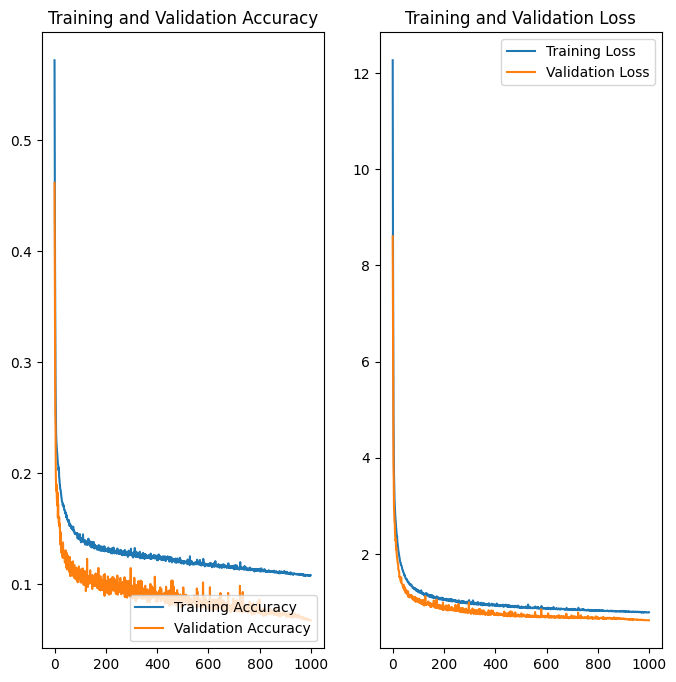

In [43]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(val_epochs)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

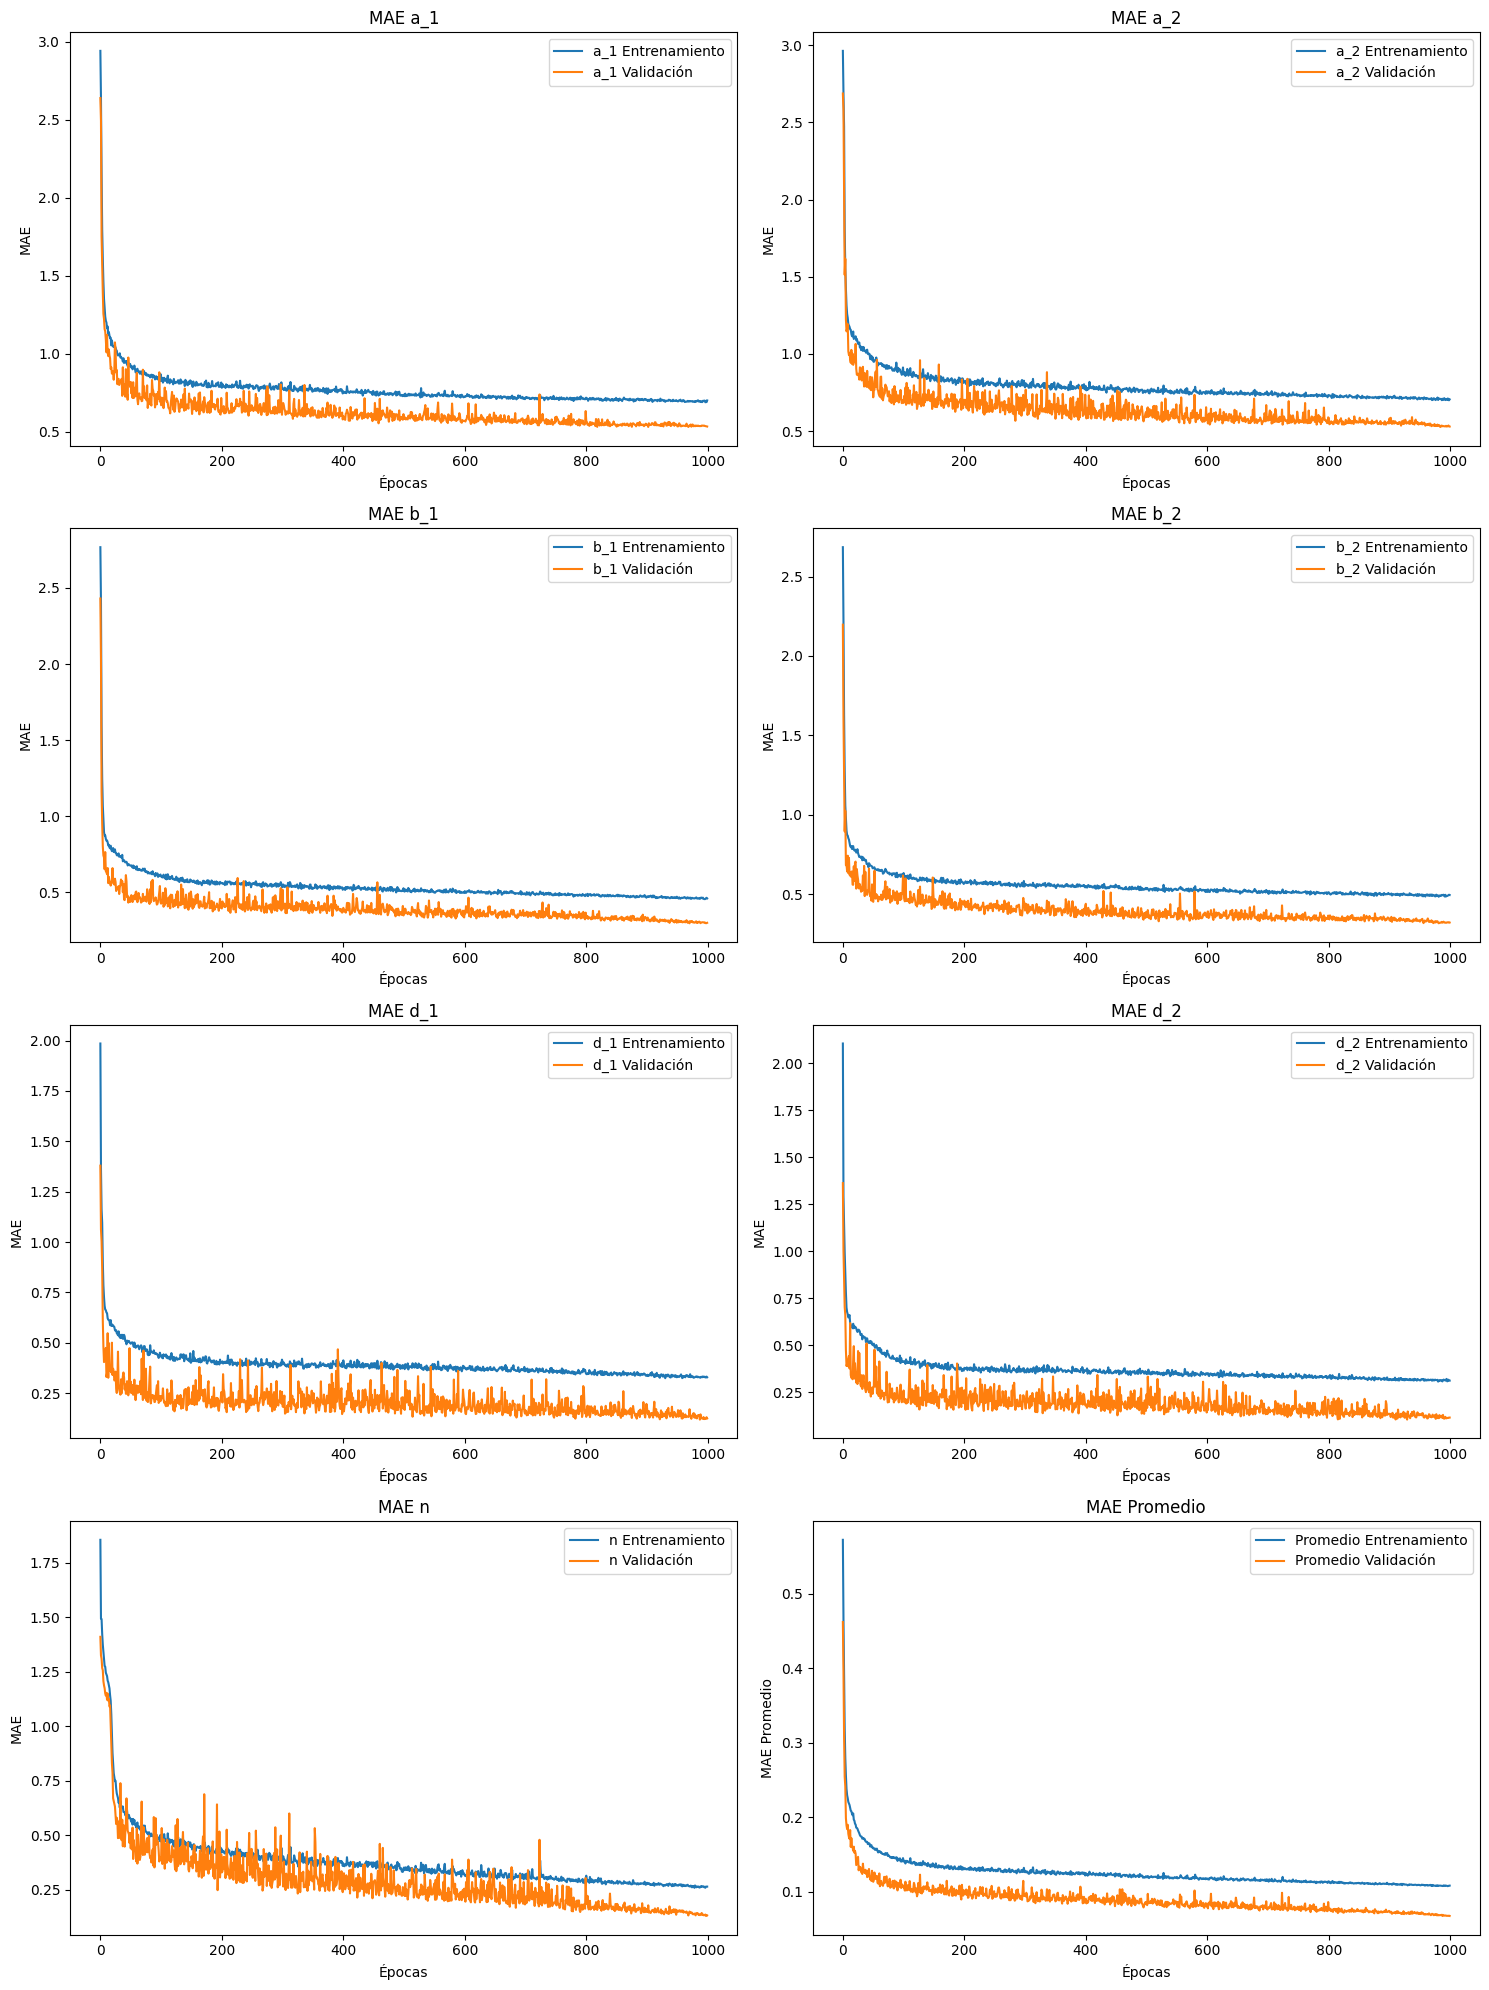

In [44]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(20, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [45]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

32/32 [==============================] - 0s 2ms/step - loss: 0.6247 - a_1: 0.5389 - a_2: 0.5384 - b_1: 0.3046 - b_2: 0.3318 - d_1: 0.1255 - d_2: 0.1156 - n: 0.1324 - mean_metric: 0.0685


In [46]:
predictions = model.predict(campvectest)

32/32 [==============================] - 0s 2ms/step


In [47]:
print(coefcampvectest[0,:])
print(predictions[0,:])
from sklearn.metrics import mean_absolute_error
print(np.sum(coefcampvectest, axis=-1))

mae1 = mean_absolute_error(coefcampvectest[0,:], predictions[0,:])
mae1

[ 7  2 10  1 10  0  1]
[6.871941   1.7324634  9.906923   0.5078638  9.848259   0.13354243
 0.87856257]
[31 32 28 49 25 38 26 42 31 27 24 18 37 33 38 30 24 36 37 38 36 33 20 37
 24 35 39 26 22 26 39 26 38 42 17 23 26 25 36 24 42 34 42 29 38 28 41 30
 34 35 42 16 26 28 40 28 32 40 28 35 28 38 34 32 42 39 38 29 33 38 34 30
 32 39 32 27 31 38 22 36 29 30 35 32 43 32 29 30 41 22 23 47 31 26 34 19
 29 42 30 22 33 38 25 29 36 41 34 40 32 35 40 39 31 38 21 37 43 40 30 41
 31 29 40 31 34 36 54 26 39 29 50 26 47 33 44 11 47 27 33 18 32 43 36 34
 30 34 38 46 24 32 21 48 41 44 42 40 35 29 34 31 33 28 37 30 29 38 35 33
 32 25 38 35 25 27 21 28 38 40 23 38 34 22 42 37 33 20 40 22 35 34 24 33
 37 31 35 31 28 23 36 34 40 25 30 31 34 39 26 26 37 36 45 34 28 30 39 37
 37 35 33 45 31 35 37 31 38 27 35 29 23 51 20 25 31 24 37 43 27 25 27 37
 26 36 36 39 34 23 24 44 31 30 43 41 31 32 40 28 40 32 36 24 47 44 20 28
 29 35 27 30 27 37 53 43 47 46 21 20 20 31 39 28 38 26 36 41 27 30 50 33
 34 37 27 35 23 37 39

0.19821847549506597

In [48]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 0.29763929852008425, Desviación estándar del error: 0.7308803704040626, Error absoluto máximo: 5.689300537109375


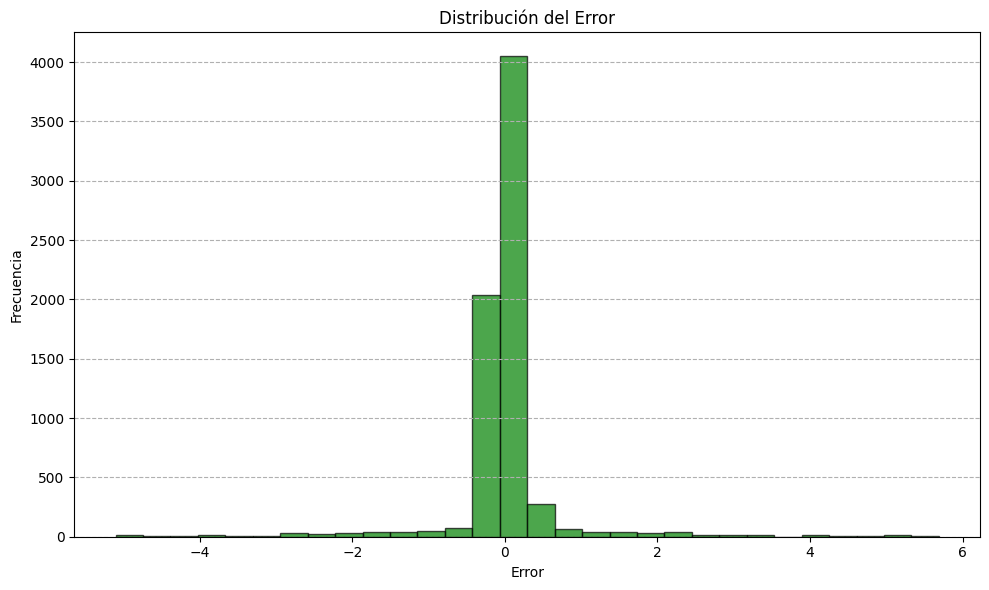

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [50]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")


MAE relativo: 0.07222587675650813
Desviación estándar del error relativo: 0.03028626594781187
Error absoluto máximo relativo: 0.19402538693469504


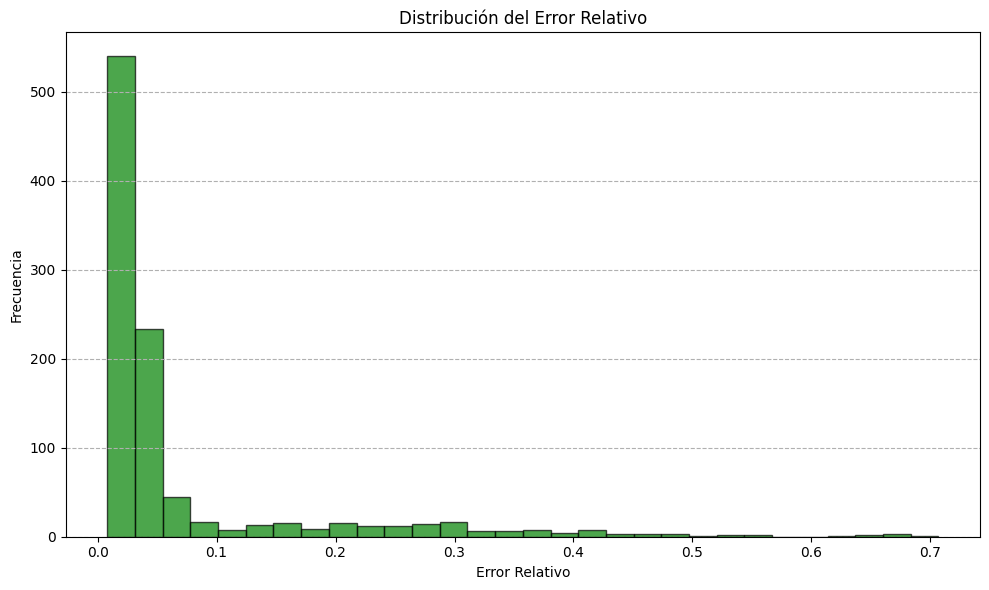

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()


# Guardamos los datos de Accuracy y Loss

In [52]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../../../Gráficas finales/grid20_traj50/historyconvcampvec20.csv', index=False)

# Guardamos el modelo

In [53]:
path_to_save = '../../../trained_models_clean/grid20_traj50/'

In [54]:
model.save(path_to_save + '/convolucionalcv20.h5')

# Importamos el modelo

In [32]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [33]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [34]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
custom_objects = {'custom_activation':custom_activation,'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)

new_model = keras.models.load_model(
    '../../../trained_models_clean/grid20_traj50/convolucionalcv20.h5', custom_objects=custom_objects)

In [35]:
new_model.summary()

Model: "sequential_308"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_447 (Conv2D)         (None, 17, 20, 58)        522       
                                                                 
 max_pooling2d_411 (MaxPooli  (None, 8, 10, 58)        0         
 ng2D)                                                           
                                                                 
 flatten_308 (Flatten)       (None, 4640)              0         
                                                                 
 dense_1681 (Dense)          (None, 28)                129948    
                                                                 
 dense_1682 (Dense)          (None, 41)                1189      
                                                                 
 dense_1683 (Dense)          (None, 120)               5040      
                                                    

# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [58]:
import random
from scipy.integrate import solve_ivp

campvec = []
coef = []
contador = 0
for i in range(0, 1):
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        # dX_dt=a1/(1+Y**n)-d1*X+b1
        # dY_dt=a2/(1+X**n)-d2*Y+b2
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 20)
    y2 = np.linspace(y_range_neg, y_range_pos, 20)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
    print(coef1)

    
campvec = np.array(campvec)
coef = np.array(coef)


--------------------------------------------
[0, 5, 7, 0, 2, 3, 3]


In [59]:
campvecnone = campvec[None, :]
campvecnone = np.transpose(campvecnone, (0,2,3,1))

## Predecimos con los datos nuevos

In [60]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(new_predictions)

1/1 [==============================] - 0s 38ms/step
[[0. 5. 7. 0. 2. 3. 3.]]


## Encontramos puntos de equilibrio datos reales

In [61]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b2
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(3.5, 0.03798670465337132)


## Graficamos con los coeficientes reales

Text(0, 0.5, 'Concentración Y')

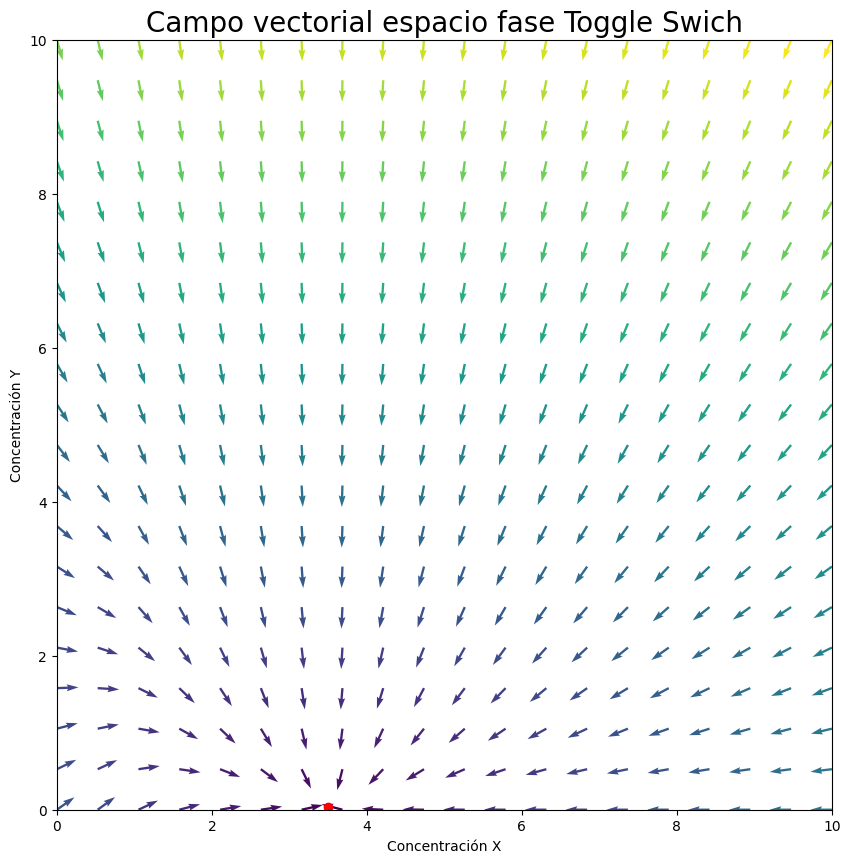

In [62]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values =primer_cuadrante_reales[1]
y1 = np.linspace(0, 10, 20)
y2 = np.linspace(0, 10, 20)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Encontramos puntos de equilibro datos predecidos

In [63]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b2pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(3.5, 0.03798670465337132)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

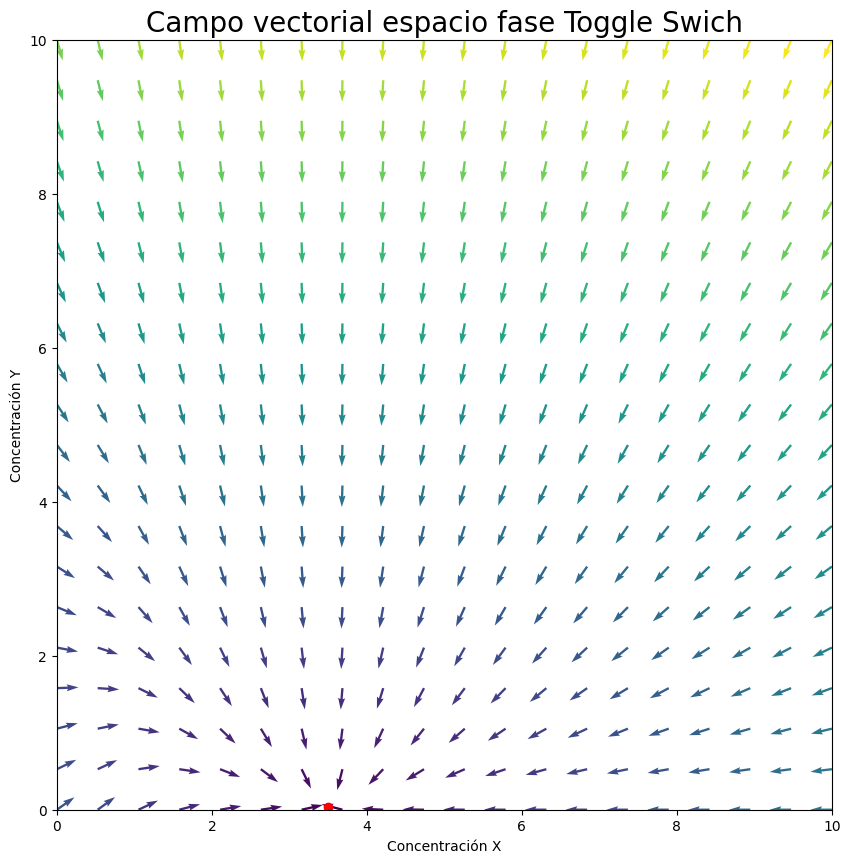

In [64]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 20)
y2pred = np.linspace(y_range_neg, y_range_pos, 20)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

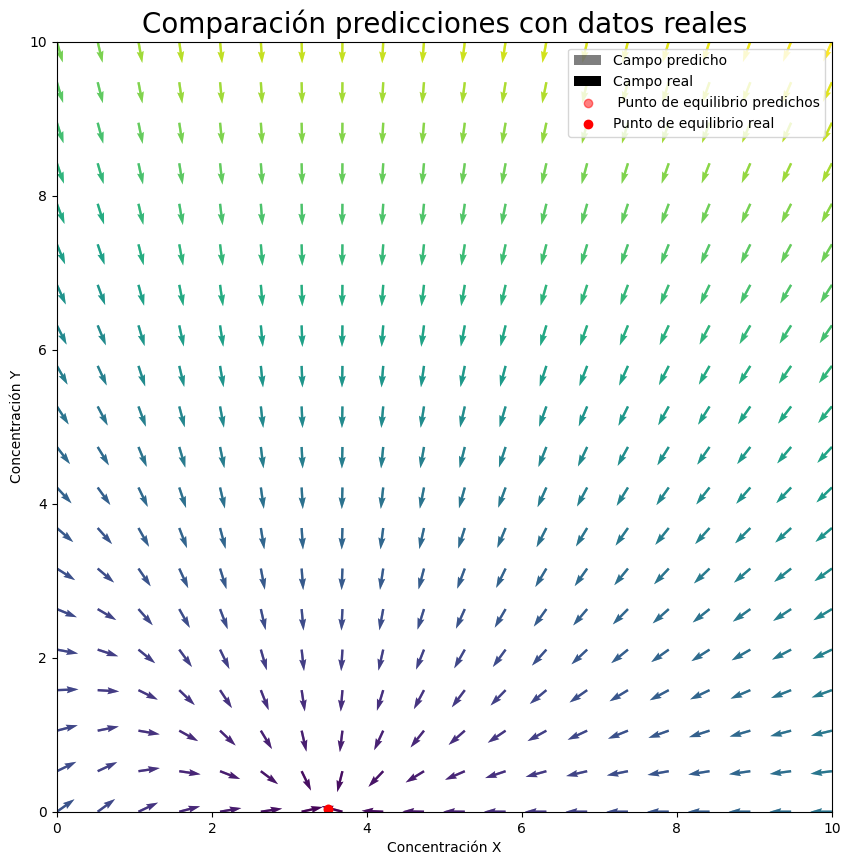

In [65]:
#%matplotlib qt
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5, label = "Campo predicho")

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1, label = "Campo real")

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5, label = " Punto de equilibrio predichos")
ax.scatter(x_values, y_values, color='red', alpha = 1, label = "Punto de equilibrio real")
ax.set_title('Comparación predicciones con datos reales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')
ax.legend(loc='upper right')  # Agregar leyenda a la gráfica
plt.show()

## Graficamos las diferencias

0.0


C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: divide by zero encountered in double_scalars
  length = a * (widthu_per_lenu / (self.scale * self.width))
C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: invalid value encountered in multiply
  length = a * (widthu_per_lenu / (self.scale * self.width))


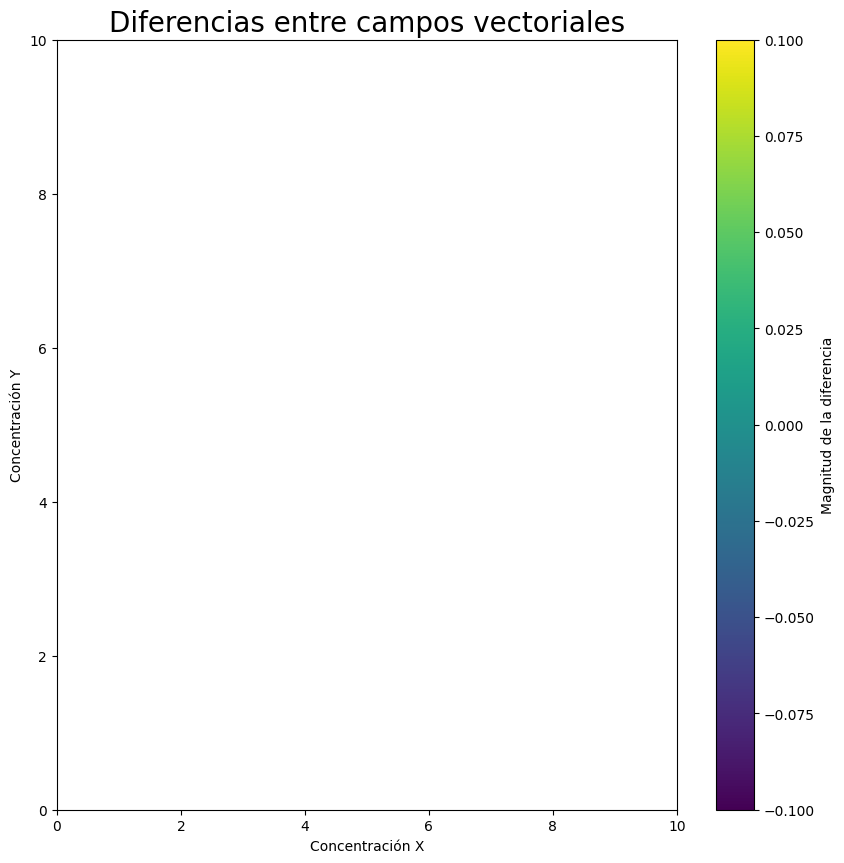

In [66]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7
u_diff2 = u_diff + epsilon
v_diff2 = v_diff + epsilon

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.
scale = 70

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

## Errores relativos

C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: divide by zero encountered in double_scalars
  length = a * (widthu_per_lenu / (self.scale * self.width))
C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: invalid value encountered in multiply
  length = a * (widthu_per_lenu / (self.scale * self.width))


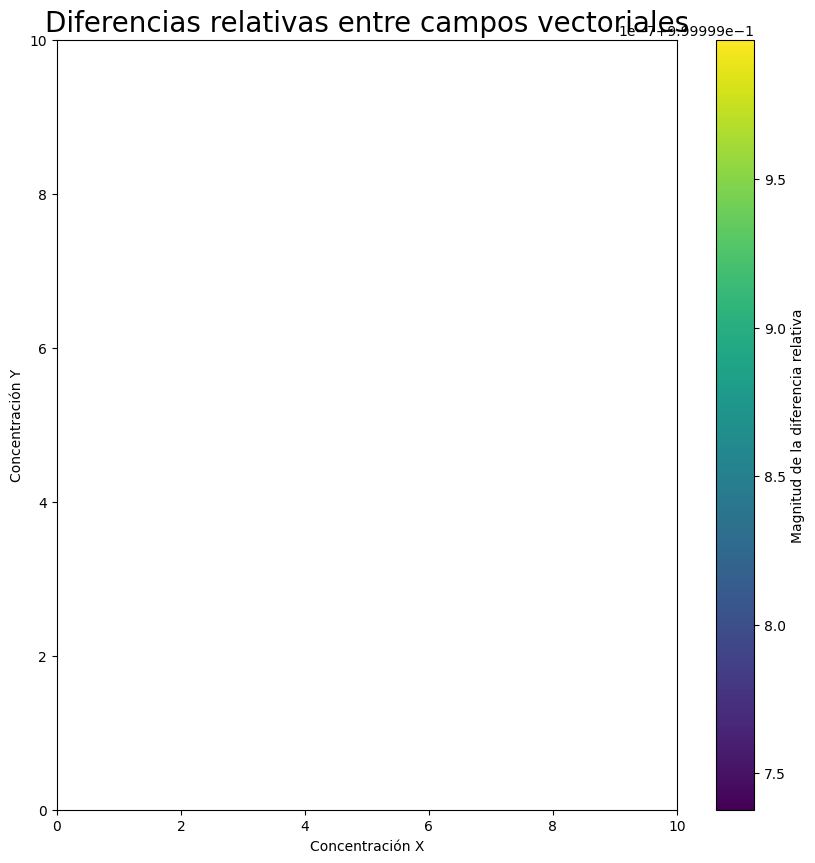

In [67]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [68]:
max_index_flattened = M_diff_rel.argmax()
max_coords = np.unravel_index(max_index_flattened, M_diff_rel.shape)
M_orig[max_coords]
print('El valor máximo de error relativo es de:', M_diff_rel.max() )
print('El valor de u1 en el error relativo máximo es:',u1[max_coords])
print('El valor de u1pred en el error relativo máximo es:',u1pred[max_coords])
print('El valor de v1 en el error relativo máximo es:',v1[max_coords])
print('El valor de v1pred en el error relativo máximo es:',v1pred[max_coords])

El valor máximo de error relativo es de: 0.9999999969410525
El valor de u1 en el error relativo máximo es: -13.0
El valor de u1pred en el error relativo máximo es: -13.0
El valor de v1 en el error relativo máximo es: -29.995004995004994
El valor de v1pred en el error relativo máximo es: -29.995004995004994


In [69]:
np.sqrt(u1pred[max_coords]**2+v1pred[max_coords]**2)/np.sqrt(u1[max_coords]**2+v1[max_coords]**2)

1.0

In [70]:
# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u, v) + epsilon
M_diff = np.hypot(u_diff, v_diff)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

# Aplicamos el filtro para la diferencia relativa mayor a 0.05
mask = M_diff_rel > 0.05

# Calculamos el porcentaje de puntos que cumplen con la condición
porcentaje = np.mean(mask) * 100

print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 es {porcentaje:.2f}%")

El porcentaje de puntos cuyo error relativo es mayor a 0.05 es 0.00%


## Simulamos 10 veces

In [71]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(10000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 20)
    y2 = np.linspace(y_range_neg, y_range_pos, 20)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
#    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    campvecnone = np.transpose(campvecnone, (0,2,3,1))
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
#    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 20)
    y2pred = np.linspace(y_range_neg, y_range_pos, 20)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    u1pred, v1pred = f(t1, [Y1, Y2])
    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred

 # Calculamos las diferencias
    u_diff = u - upred
    v_diff = v - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(u, v) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")


--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 5 es 0.00%
--------------------------------------------
1/1 [==============================

El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 89 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 90 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 91 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 92 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 93 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 134 es 1.75%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 135 es 30.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 136 es 6.25%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 137 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 138 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de 

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 222 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 223 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 224 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 225 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 226 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de p

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 310 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 311 es 1.50%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 312 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 313 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 314 es 13.75%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de 

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 398 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 399 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 400 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 401 es 1.75%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 402 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de p

... (208 outputs left out)

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9838 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9839 es 4.25%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9840 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9841 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 22ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9842 es 46.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaj

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9882 es 13.50%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9883 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9884 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9885 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9886 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaj

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9926 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9927 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9928 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9929 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9930 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje

El promedio de los porcentajes es 2.87%


El promedio de los porcentajes es 2.87%


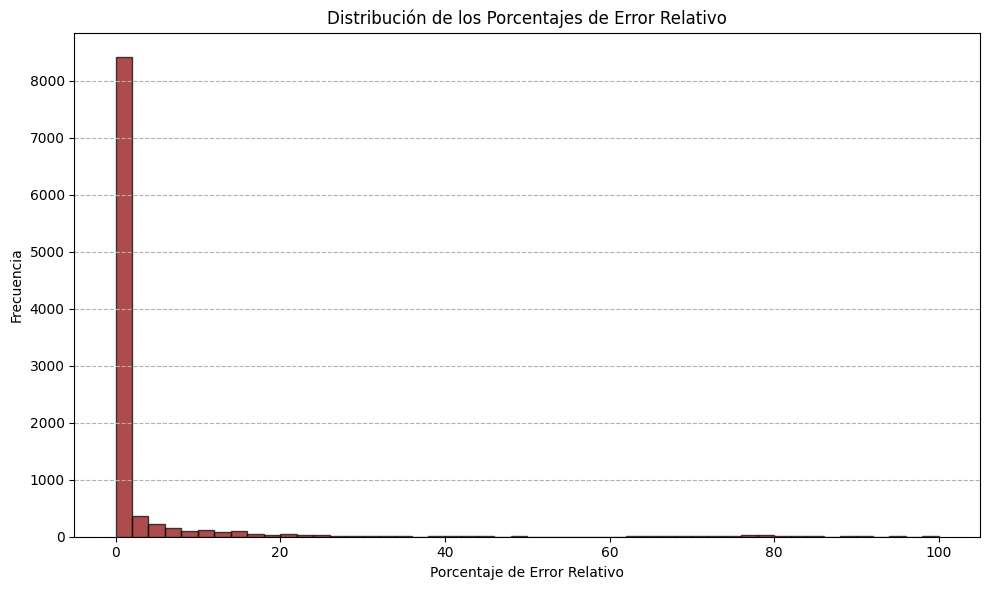

In [72]:
import matplotlib.pyplot as plt

# ...

# Muestra todos los porcentajes al final
# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

# Crea un histograma de los porcentajes
plt.figure(figsize=(10, 6))
plt.hist(porcentajes, bins=50, edgecolor='black', alpha=0.7, color = 'darkred')
plt.title('Distribución de los Porcentajes de Error Relativo')
plt.xlabel('Porcentaje de Error Relativo')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()


# Pruebas 

In [ ]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(10000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 20)
    y2 = np.linspace(y_range_neg, y_range_pos, 20)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
#    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    campvecnone = np.transpose(campvecnone, (0,2,3,1))
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
#    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 20)
    y2pred = np.linspace(y_range_neg, y_range_pos, 20)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    u1pred, v1pred = f(t1, [Y1, Y2])
    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred

 # Calculamos las diferencias
    u_diff = u - upred
    v_diff = v - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(u, v) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")
